# 03 - Propensity modelling

Time-based snapshots, leakage-safe labels, model comparison, calibration and SHAP (`src/ecom/models`).

In [1]:
import json
import pandas as pd
from IPython.display import Image, Markdown, display
from ecom.config import get_config
from ecom.layout import outputs_dir, table_path
cfg = get_config()
OUT = outputs_dir(cfg)
FIG = cfg.paths.figures
pd.set_option("display.float_format", "{:,.4f}".format)
print(f"source={cfg.source} sample={cfg.sample_rate:.0%} outputs={OUT}")

source=synthetic sample=100% outputs=D:\smaiproj\data\outputs\synthetic\full


In [2]:
from ecom.models.data import load_splits
splits = load_splits(cfg)
pd.DataFrame({s: {'users': len(getattr(splits, s)), 'positive_rate': getattr(splits, s).label.mean()} for s in ('train', 'valid', 'test')}).T

,users,positive_rate
train,"177,073.0000",0.0368
valid,"190,104.0000",0.0400
test,"209,548.0000",0.0395


## Load the registered champion from MLflow and re-score the test snapshot

In [3]:
import mlflow
from ecom.models.evaluate import classification_metrics
champ = json.loads((OUT / 'champion.json').read_text())
mlflow.set_tracking_uri(cfg.mlflow_uri)
model = mlflow.sklearn.load_model(champ['uri'])
X, y = splits.xy('test')
pd.Series(classification_metrics(y, model.predict_proba(X)[:, 1]))

roc_auc                      0.8232
pr_auc                       0.2682
brier                        0.0344
log_loss                     0.1398
base_rate                    0.0395
top_decile_precision         0.1964
top_decile_lift              4.9770
top_decile_recall            0.4977
n                      209,548.0000
dtype: float64

## Model comparison

In [4]:
pd.read_csv(OUT / "model_comparison.csv")

,model,key,valid_pr_auc,test_pr_auc,test_roc_auc,test_brier,test_log_loss,test_top_decile_precision,test_top_decile_lift,test_top_decile_recall,test_base_rate,train_seconds,champion
0,H2O AutoML leader,h2o_automl,0.2835,0.2726,0.8241,0.0330,0.1330,0.1981,5.0217,0.5022,0.0395,"1,210.9671",False
1,XGBoost + Optuna,xgboost,0.2863,0.2682,0.8232,0.0344,0.1398,0.1964,4.9770,0.4977,0.0395,616.2789,True
2,Logistic regression,logreg,0.2786,0.2676,0.8223,0.0332,0.1335,0.1996,5.0592,0.5059,0.0395,4.8819,False
3,Spark MLlib GBT,spark_gbt,0.2762,0.2561,0.8221,0.0336,0.1413,0.1967,4.9854,0.4985,0.0395,59.9506,False


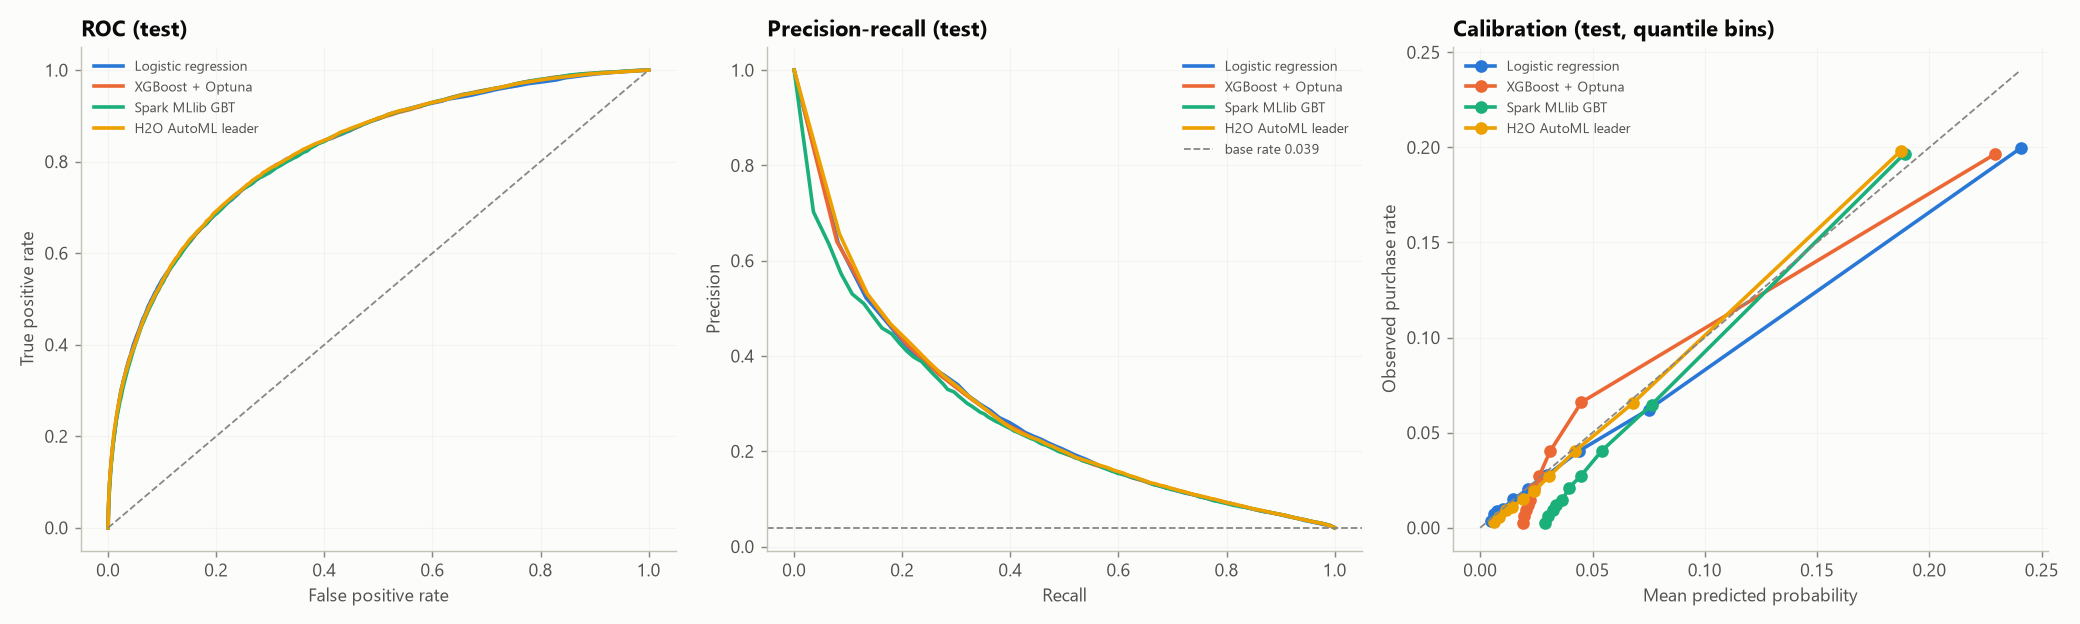

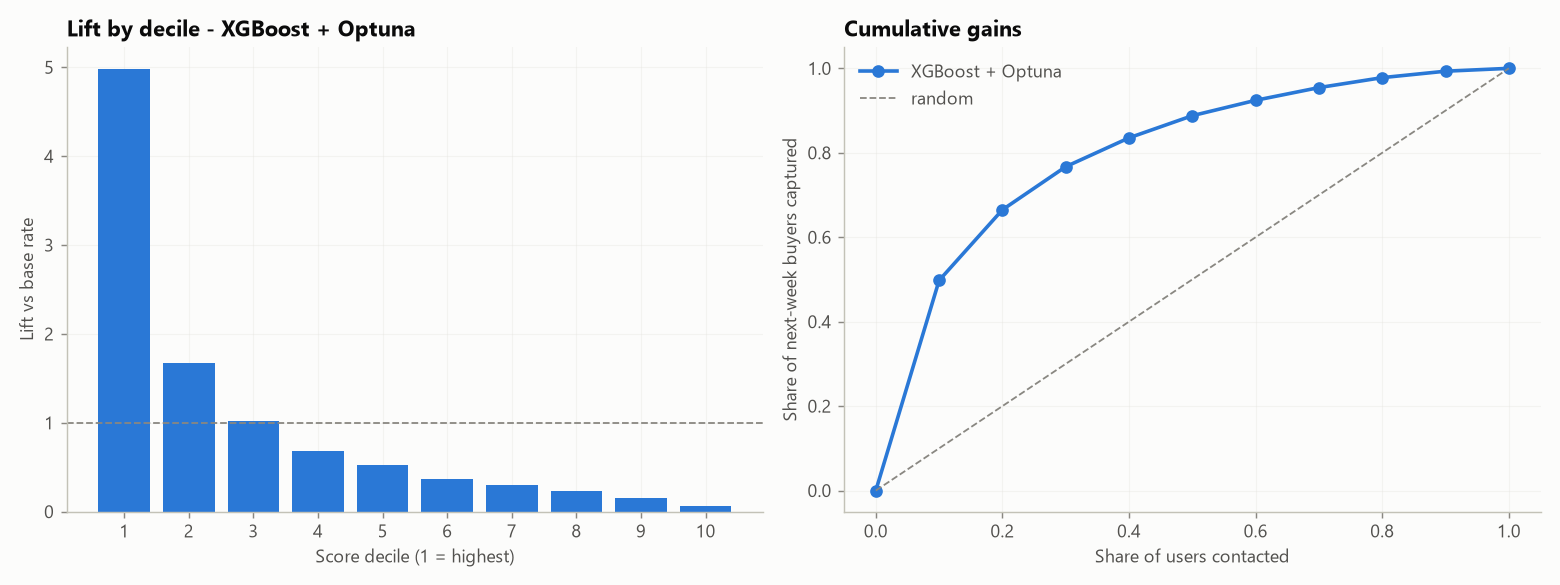

In [5]:
display(Image(FIG / "model_curves.png"))
display(Image(FIG / "model_gains.png"))

## Drivers (SHAP)

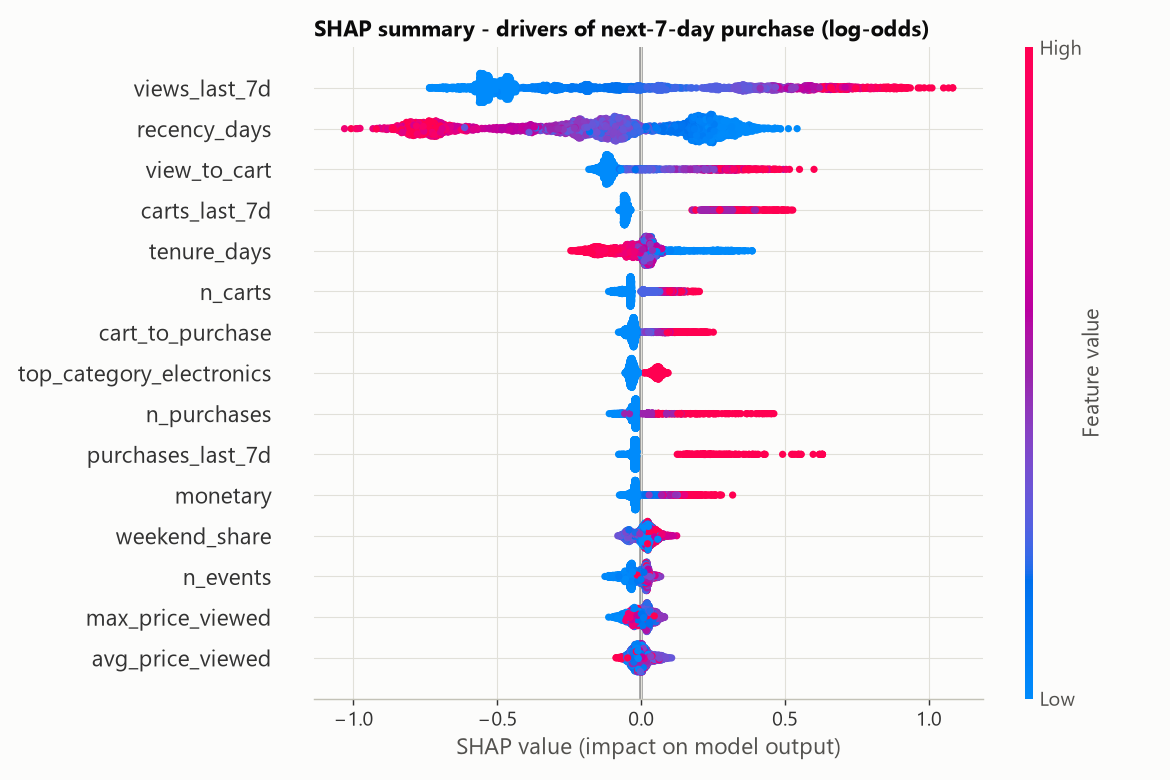

- Views in the last 7 days: the more of it, the higher the chance of buying next week. Users in the top quartile have 3.00x the purchase odds of users in the bottom quartile.
- Days since the user's last visit: the more of it, the lower the chance of buying next week. Users in the top quartile have 0.39x the purchase odds of users in the bottom quartile.
- View-to-cart rate: the more of it, the higher the chance of buying next week. Users in the top quartile have 1.38x the purchase odds of users in the bottom quartile.
- Add-to-carts in the last 7 days: the more of it, the higher the chance of buying next week. Users in the top quartile have 1.05x the purchase odds of users in the bottom quartile.
- Days since the user was first seen in the window: the more of it, the lower the chance of buying next week. Users in the top quartile have 0.81x the purchase odds of users in the bottom quartile.


In [6]:
display(Image(FIG / "shap_summary.png"))
for d in json.loads((OUT / "model_drivers.json").read_text()):
    print('-', d['text'])

## H2O AutoML leaderboard

In [7]:
pd.read_csv(OUT / "h2o_leaderboard.csv").head(10)

,model_id,aucpr,auc,logloss,mean_per_class_error,rmse,mse
0,StackedEnsemble_AllModels_3_AutoML_1_20261101_...,0.2835,0.8288,0.1334,0.3423,0.1827,0.0334
1,StackedEnsemble_AllModels_5_AutoML_1_20261101_...,0.2819,0.8266,0.1417,0.3442,0.1878,0.0353
2,StackedEnsemble_AllModels_2_AutoML_1_20261101_...,0.2805,0.8289,0.1337,0.3342,0.1829,0.0335
3,StackedEnsemble_AllModels_1_AutoML_1_20261101_...,0.2796,0.8285,0.1338,0.3407,0.1830,0.0335
4,StackedEnsemble_BestOfFamily_6_AutoML_1_202611...,0.2795,0.8280,0.1346,0.3434,0.1835,0.0337
5,StackedEnsemble_BestOfFamily_4_AutoML_1_202611...,0.2795,0.8279,0.1339,0.3375,0.1829,0.0335
6,StackedEnsemble_BestOfFamily_3_AutoML_1_202611...,0.2776,0.8285,0.1340,0.3466,0.1832,0.0335
7,StackedEnsemble_BestOfFamily_2_AutoML_1_202611...,0.2775,0.8285,0.1339,0.3464,0.1831,0.0335
8,GBM_grid_1_AutoML_1_20261101_74443_model_20,0.2773,0.8252,0.1345,0.3414,0.1831,0.0335
9,StackedEnsemble_BestOfFamily_1_AutoML_1_202611...,0.2757,0.8273,0.1343,0.3413,0.1833,0.0336
